# ----Data Preparation----

In [1]:
# Upload the data
import pandas as pd
df = pd.read_json("yorumlar.csv", lines=True)
df.head()

,cid,text,time,author,channel,votes,replies,photo,heart,reply,time_parsed
0,UgyTIa2OAGoIJJovNuR4AaABAg,I need this 😩,3 saat önce,@nordiasamuels5170,UCn4PNTfykIUSQG5Kg9Agurg,0,,https://yt3.ggpht.com/ytc/AIdro_lgr_XIl-Qry-E7...,False,False,1.793546e+09
1,UgxT8eAZpquz-27L-1J4AaABAg,This has a lot of great features. Love the ste...,5 saat önce,@amysessentialsreviews,UCqSzM5ewehcuNHZrfCJCXjQ,0,,https://yt3.ggpht.com/Hda1yP42E78TqXac6LhSP7yl...,False,False,1.793539e+09
2,UgyQZym8e7SrxrKSXU14AaABAg,Can I have it for free?,10 saat önce,@AnonymousnessUser,UCy0Bt4Y5LNorn8DvIOGPu0w,0,,https://yt3.ggpht.com/5i7jMR9QsRpxwnrdHHNOJhdB...,False,False,1.793521e+09
3,UgyfpPzMtzPoxIvhy-J4AaABAg,does this have greenlines with overheated too?😂😂,11 saat önce,@raphaeltheantisocial2805,UCIeEAGi7Uk7uxmWTZaTjOJQ,0,,https://yt3.ggpht.com/o3aaOwPai62FTMH7jNcnPlHv...,False,False,1.793517e+09
4,Ugyk6tr_GhcZHXhpZsN4AaABAg,This look great…,1 gün önce,@MsDuchess1972,UCCOToT3MQh3hpMaMw5O0-LA,0,,https://yt3.ggpht.com/ytc/AIdro_k0LydOqP2lBSyQ...,False,False,1.793471e+09


In [2]:
# Remove the bot comments

In [3]:
print(f"first lenght of the data set: {len(df)}")
      
df.dropna(subset =['text'], inplace=True)
df.drop_duplicates(subset=['author', 'text'], keep='first', inplace=True)

df['text_len'] = df['text'].astype(str).str.len()
duplicates = df[df['text_len']>20].duplicated(subset=['text'], keep='first')
df = df[~df.index.isin(duplicates[duplicates].index)].copy()

print(f"Lenght of the dataset after removing duplicates: {len(df)}")


first lenght of the data set: 3630
Lenght of the dataset after removing duplicates: 3591


In [4]:
# Create new collumn for the emojis.

In [5]:
import re
df['emojis'] = df['text'].apply(
    lambda x: ''.join(re.findall(r'[^\w\s,.\'"!?-]', str(x)))
)
df.head()

,cid,text,time,author,channel,votes,replies,photo,heart,reply,time_parsed,text_len,emojis
0,UgyTIa2OAGoIJJovNuR4AaABAg,I need this 😩,3 saat önce,@nordiasamuels5170,UCn4PNTfykIUSQG5Kg9Agurg,0,,https://yt3.ggpht.com/ytc/AIdro_lgr_XIl-Qry-E7...,False,False,1.793546e+09,13,😩
1,UgxT8eAZpquz-27L-1J4AaABAg,This has a lot of great features. Love the ste...,5 saat önce,@amysessentialsreviews,UCqSzM5ewehcuNHZrfCJCXjQ,0,,https://yt3.ggpht.com/Hda1yP42E78TqXac6LhSP7yl...,False,False,1.793539e+09,114,🔥🔥🔥
2,UgyQZym8e7SrxrKSXU14AaABAg,Can I have it for free?,10 saat önce,@AnonymousnessUser,UCy0Bt4Y5LNorn8DvIOGPu0w,0,,https://yt3.ggpht.com/5i7jMR9QsRpxwnrdHHNOJhdB...,False,False,1.793521e+09,23,
3,UgyfpPzMtzPoxIvhy-J4AaABAg,does this have greenlines with overheated too?😂😂,11 saat önce,@raphaeltheantisocial2805,UCIeEAGi7Uk7uxmWTZaTjOJQ,0,,https://yt3.ggpht.com/o3aaOwPai62FTMH7jNcnPlHv...,False,False,1.793517e+09,48,😂😂
4,Ugyk6tr_GhcZHXhpZsN4AaABAg,This look great…,1 gün önce,@MsDuchess1972,UCCOToT3MQh3hpMaMw5O0-LA,0,,https://yt3.ggpht.com/ytc/AIdro_k0LydOqP2lBSyQ...,False,False,1.793471e+09,16,…


In [6]:
# Language detection preparation
def prepare_for_lang_detect(text):
    text = str(text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text=re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['text_no_emoji'] = df['text'].apply(prepare_for_lang_detect)
df.head()

,cid,text,time,author,channel,votes,replies,photo,heart,reply,time_parsed,text_len,emojis,text_no_emoji
0,UgyTIa2OAGoIJJovNuR4AaABAg,I need this 😩,3 saat önce,@nordiasamuels5170,UCn4PNTfykIUSQG5Kg9Agurg,0,,https://yt3.ggpht.com/ytc/AIdro_lgr_XIl-Qry-E7...,False,False,1.793546e+09,13,😩,I need this
1,UgxT8eAZpquz-27L-1J4AaABAg,This has a lot of great features. Love the ste...,5 saat önce,@amysessentialsreviews,UCqSzM5ewehcuNHZrfCJCXjQ,0,,https://yt3.ggpht.com/Hda1yP42E78TqXac6LhSP7yl...,False,False,1.793539e+09,114,🔥🔥🔥,This has a lot of great features Love the stea...
2,UgyQZym8e7SrxrKSXU14AaABAg,Can I have it for free?,10 saat önce,@AnonymousnessUser,UCy0Bt4Y5LNorn8DvIOGPu0w,0,,https://yt3.ggpht.com/5i7jMR9QsRpxwnrdHHNOJhdB...,False,False,1.793521e+09,23,,Can I have it for free
3,UgyfpPzMtzPoxIvhy-J4AaABAg,does this have greenlines with overheated too?😂😂,11 saat önce,@raphaeltheantisocial2805,UCIeEAGi7Uk7uxmWTZaTjOJQ,0,,https://yt3.ggpht.com/o3aaOwPai62FTMH7jNcnPlHv...,False,False,1.793517e+09,48,😂😂,does this have greenlines with overheated too
4,Ugyk6tr_GhcZHXhpZsN4AaABAg,This look great…,1 gün önce,@MsDuchess1972,UCCOToT3MQh3hpMaMw5O0-LA,0,,https://yt3.ggpht.com/ytc/AIdro_k0LydOqP2lBSyQ...,False,False,1.793471e+09,16,…,This look great


In [7]:
# Language detection: We are keeping only english texts
#!pip install langdetect

In [8]:
from langdetect import DetectorFactory, detect

DetectorFactory.seed = 42


def is_english(text):
  try:
    if len(text) < 3:
      return False
    return detect(text) == 'en'
  except:
    return False


df = df[df['text_no_emoji'].apply(is_english)].copy()
df.reset_index(drop=True, inplace=True)

print(f'Lenght of the dataset after the language detection: {len(df)}')

Lenght of the dataset after the language detection: 2671


In [9]:
spam_patterns = [
    r'who is watching',
    r'anyone watching',
    r'who\'s here',
    r'like if you',
    r'early gang',
    r'notification squad',
]
df = df[
    ~df['text_no_emoji']
    .str.lower()
    .str.contains('|'.join(spam_patterns), regex=True)
].copy()

keep_cols = ['text', 'text_no_emoji', 'emojis', 'time', 'author', 'votes']
df = df[[col for col in keep_cols if col in df.columns]].copy()

if 'votes' in df.columns:
  df['votes'] = pd.to_numeric(df['votes'], errors='coerce').fillna(0)

df.reset_index(drop=True, inplace=True)
print(f'Comment count ready for modelling: {len(df)}')

Comment count ready for modelling: 2669


# ----Calculate Sentiment Scores----

In [10]:
#!pip install nltk

In [11]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer

nltk.download('vader_lexicon')

sia = SentimentIntensityAnalyzer()


def get_sentiment(text):
  score = sia.polarity_scores(str(text))['compound']
  if score >= 0.05:
    label = 'Positive'
  elif score <= -0.05:
    label = 'Negative'
  else:
    label = 'Neutral'
  return pd.Series([score, label])


df[['sentiment_score', 'sentiment_label']] = df['text'].apply(get_sentiment)
average_sentiment = df['sentiment_score'].mean()

print((df['sentiment_label'].value_counts(normalize=True) * 100).map('{:.2f}%'.format))
print(f"Avrage sentiment score: {average_sentiment:.3f}")
df[['text', 'sentiment_score', 'sentiment_label']].head(10)

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\ruvey\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


Positive    41.96%
Neutral     39.42%
Negative    18.62%
Name: sentiment_label, dtype: object
Avrage sentiment score: 0.137


,text,sentiment_score,sentiment_label
0,I need this 😩,0.0000,Neutral
1,This has a lot of great features. Love the ste...,0.9060,Positive
2,Can I have it for free?,0.5106,Positive
3,does this have greenlines with overheated too?😂😂,0.0000,Neutral
4,This look great…,0.0000,Neutral
5,honestly it sounds amazing but some of the tin...,0.9253,Positive
6,I want this phone,0.0772,Positive
7,Coming from Xiamoi note 10s.Had bought my firs...,0.9557,Positive
8,No more pictures in the dark!,-0.3595,Negative
9,Well time for upgrade just after paying off my...,0.4404,Positive


# Which aspects have been talked in the comments?

In [12]:
aspects = {
    'Camera': [
        'camera',
        'zoom',
        'photo',
        'video',
        'lens',
        'megapixel',
        'mp',
        'nightography',
        'selfie',
    ],
    'AI & Software': [
        'ai',
        'galaxy ai',
        'artificial intelligence',
        'software',
        'one ui',
        'update',
        'feature',
        'smart',
    ],
    'Price & Value': [
        'price',
        'expensive',
        'overpriced',
        'cost',
        'worth',
        'money',
        'cheap',
        'upgrade',
        'trade-in',
        'dollar',
        '$',
    ],
    'Design & Display': [
        'design',
        'screen',
        'display',
        'bezels',
        'titanium',
        'color',
        'look',
        'thin',
        'heavy',
        'same',
    ],
    'Battery & Performance': [
        'battery',
        'charge',
        'charging',
        'chip',
        'snapdragon',
        'exynos',
        'fast',
        'lag',
        'heat',
        'overheating',
    ],
    'Competitor (Apple/iPhone)': [
        'apple',
        'iphone',
        'ios',
        'pixel',
        'google',
        'copy',
        'copied',
    ],
}

def detect_aspects(text):
  text_lower = str(text).lower()
  matched = []
  for aspect, keywords in aspects.items():
    if any(
        re.search(r'\b' + re.escape(kw) + r'\b', text_lower) for kw in keywords
    ):
      matched.append(aspect)
  return matched if matched else ['General']


df['aspects'] = df['text_no_emoji'].apply(detect_aspects)


df_exploded = df.explode('aspects')

aspect_summary = (
    df_exploded.groupby('aspects')
    .agg(
        total_mentions=('sentiment_score', 'count'),
        avg_sentiment=('sentiment_score', 'mean'),
        positive_pct=(
            'sentiment_label',
            lambda x: (x == 'Positive').mean() * 100,
        ),
        negative_pct=(
            'sentiment_label',
            lambda x: (x == 'Negative').mean() * 100,
        ),
        total_likes=('votes', 'sum'),
    )
    .sort_values(by='total_mentions', ascending=False)
)

print('--- ASPECT BASED Sentiment Analysis ---')
print(aspect_summary.round(2))

--- ASPECT BASED Sentiment Analysis ---
                           total_mentions  avg_sentiment  positive_pct  \
aspects                                                                  
General                              1352           0.13         38.91   
Design & Display                      564           0.18         51.24   
Competitor (Apple/iPhone)             376           0.15         40.43   
AI & Software                         364           0.18         48.08   
Price & Value                         222           0.15         50.90   
Camera                                169           0.31         60.95   
Battery & Performance                 167           0.20         53.29   

                           negative_pct  total_likes  
aspects                                               
General                           17.09       4570.0  
Design & Display                  20.92       2278.0  
Competitor (Apple/iPhone)         17.02        982.0  
AI & Software     

In [13]:
#df.to_csv('samsung_sentiment_analyzed.csv', index=False, encoding='utf-8-sig')

In [14]:
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

custom_stop_words = list(ENGLISH_STOP_WORDS) + ['th', 'march', 'phone', 'samsung', 'galaxy', 'ultra']

neg_texts = df[df['sentiment_label'] == 'Negative']['text_no_emoji']

vec = CountVectorizer(ngram_range=(2, 2), stop_words=custom_stop_words, max_features=15)
X = vec.fit_transform(neg_texts)

bigrams = pd.DataFrame(
    {'phrase': vec.get_feature_names_out(), 'count': X.sum(axis=0).A1}
).sort_values(by='count', ascending=False).reset_index(drop=True)

print('\n--- Frequently Used 15 Negative Phrases ---')
print(bigrams.to_string(index=False))


--- Frequently Used 15 Negative Phrases ---
          phrase  count
  privacy screen     19
   bluetooth pen     13
 privacy display     12
screen protector     11
      green line      9
customer service      6
         hate ai      6
     ai features      5
  bluetooth spen      5
         don buy      5
     mah battery      5
   pen bluetooth      5
         pro max      5
         sd card      5
  spen bluetooth      5


# Graphic Display

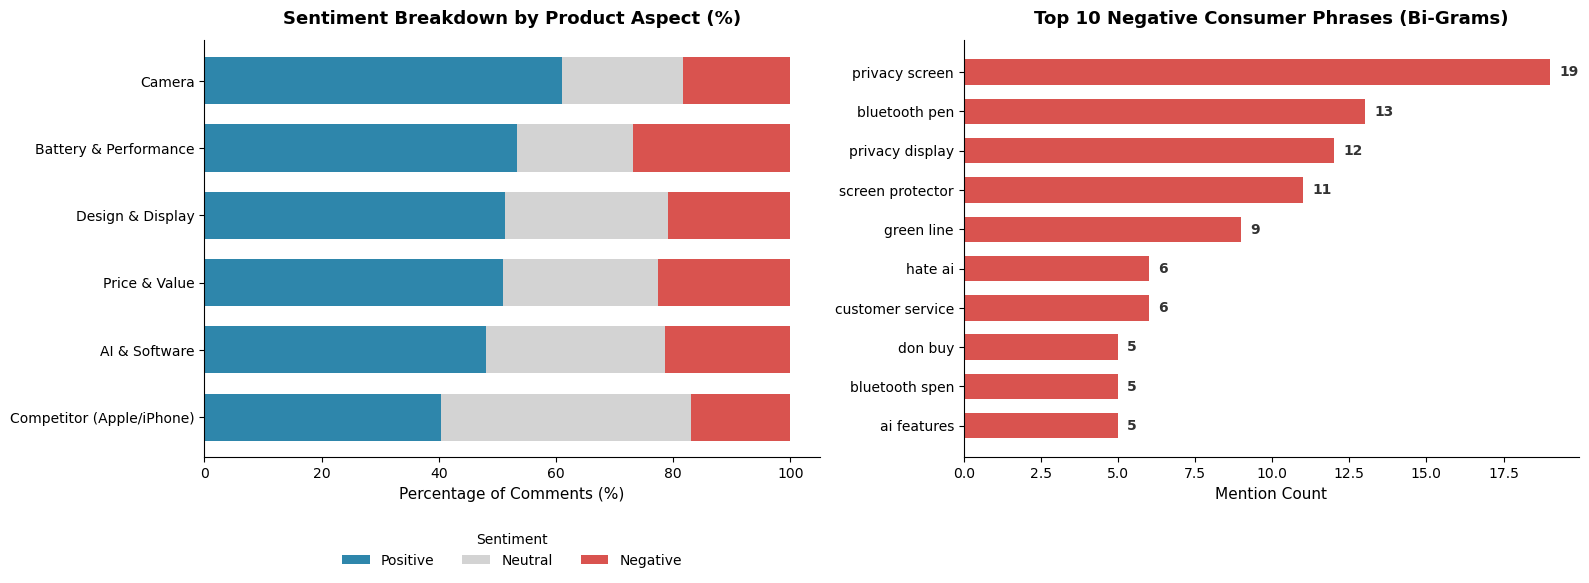

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_exp = df.explode('aspects')
df_exp = df_exp[df_exp['aspects'] != 'General']

aspect_ct = pd.crosstab(df_exp['aspects'], df_exp['sentiment_label'], normalize='index') * 100
aspect_ct = aspect_ct[['Positive', 'Neutral', 'Negative']].sort_values(by='Positive', ascending=True)

colors = ['#2E86AB', '#D3D3D3', '#D9534F']
aspect_ct.plot(kind='barh', stacked=True, color=colors, ax=axes[0], width=0.7)

axes[0].set_title('Sentiment Breakdown by Product Aspect (%)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Percentage of Comments (%)', fontsize=11)
axes[0].set_ylabel('')
axes[0].legend(title='Sentiment', bbox_to_anchor=(0.5, -0.15), loc='upper center', ncol=3, frameon=False)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

top_neg = bigrams.head(10).sort_values(by='count', ascending=True)

axes[1].barh(top_neg['phrase'], top_neg['count'], color='#D9534F', height=0.65)
axes[1].set_title('Top 10 Negative Consumer Phrases (Bi-Grams)', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Mention Count', fontsize=11)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

for index, value in enumerate(top_neg['count']):
    axes[1].text(value + 0.3, index, str(value), va='center', fontsize=10, fontweight='bold', color='#333333')

plt.tight_layout()
plt.savefig('samsung_s26_sentiment_charts.png', dpi=300, bbox_inches='tight')
plt.show()

# ---- Executive Summary ----

    This sentiment analysis was conducted to evaluate the consumer perception of Samsung smartphone launch. The data is from comments of the following youtube video "https://youtu.be/2gYqEi8-am4?si=-LiqYmAXNNEB1zBc". After the cleansing and preparing the data 2669 comments analyzed by using VADER sentiment scoring and aspect-based text mining.
    
    Overall distribution of the sentiments were found as 41.96% Positive, 39.42% Neutral, and 18.62% Negative comments with an Average Compound Score of 0.137. Even though the avarage compound score is close to a neutral sentiment, as well we can say that the overall launch performance is still looks positive because of the two-to-one ratio between positive and negative sentiments.
    
    The other thing we did was attaining different categories of aspects from the comments we decided for 6 categories(Camera, Ai & Software, Design & Display, Competitor, Price & Value, and lastly Battery & Performance) and some keywords that represent the categories. Most positively mentioned aspect is Camera(60.95%) quality and the customers mostly mentioned Battery & Performance(26.95%) as a complaint. 
    
    An interesting part is that mostly liked negatively mentioned aspect is about design & display. That is not surprising, though, because when we look at the 15 most frequently used negative phrases table, we see that two of the top three negative feedback items are related to privacy display and privacy screen. The reason for this is that the built-in privacy screen of the Galaxy S26 raised some questions among consumers.
    
    Additionally, we see that the loyal customers of Samsung are complaining about the Galaxy S26 not having a S-pen which customers belive that one thing that makes the brand so unique. 


# ----Recommendations----

    A: Samsung should immediately release a short-form FAQ video to clarify how the Privacy Display works and address consumers' questions and concerns.
    
    B: For the loyal S Pen community, Samsung should relay this feedback to the product team and take it into consideration for future product iterations. Even a limited-edition Galaxy model equipped with an S Pen could help Samsung win back the hearts of its most loyal customers.